In [4]:
import numpy as np
import matplotlib.pyplot as plt

def draw_half_pitch(ax, length=52.5, width=68.0):
    half_w = width / 2
    goal_half = 7.32 / 2          # 3.66
    six_depth = 5.5
    six_half = 18.32 / 2          # 9.16
    pen_depth = 16.5
    pen_half = 40.32 / 2          # 20.16
    pen_spot = 11.0
    arc_r = 9.15

    # contur teren (jumătate)
    ax.plot([0, length, length, 0, 0],
            [-half_w, -half_w, half_w, half_w, -half_w], linewidth=2)

    # linia porții + linia de la mijloc
    ax.axvline(0, linewidth=2)
    ax.axvline(length, linewidth=2)

    # poarta (segment pe linia porții)
    ax.plot([0, 0], [-goal_half, goal_half], linewidth=6)

    # careu 6m
    ax.plot([0, six_depth, six_depth, 0],
            [-six_half, -six_half, six_half, six_half], linewidth=2)

    # careu 16.5m (penalty area)
    ax.plot([0, pen_depth, pen_depth, 0],
            [-pen_half, -pen_half, pen_half, pen_half], linewidth=2)

    # punctul de la 11m
    ax.scatter([pen_spot], [0], s=25)

    # arcul de la 16m ("D") – doar partea din afara careului
    theta = np.linspace(-np.pi/2, np.pi/2, 300)
    arc_x = pen_spot + arc_r * np.cos(theta)
    arc_y = arc_r * np.sin(theta)
    mask = arc_x >= pen_depth
    ax.plot(arc_x[mask], arc_y[mask], linewidth=2)

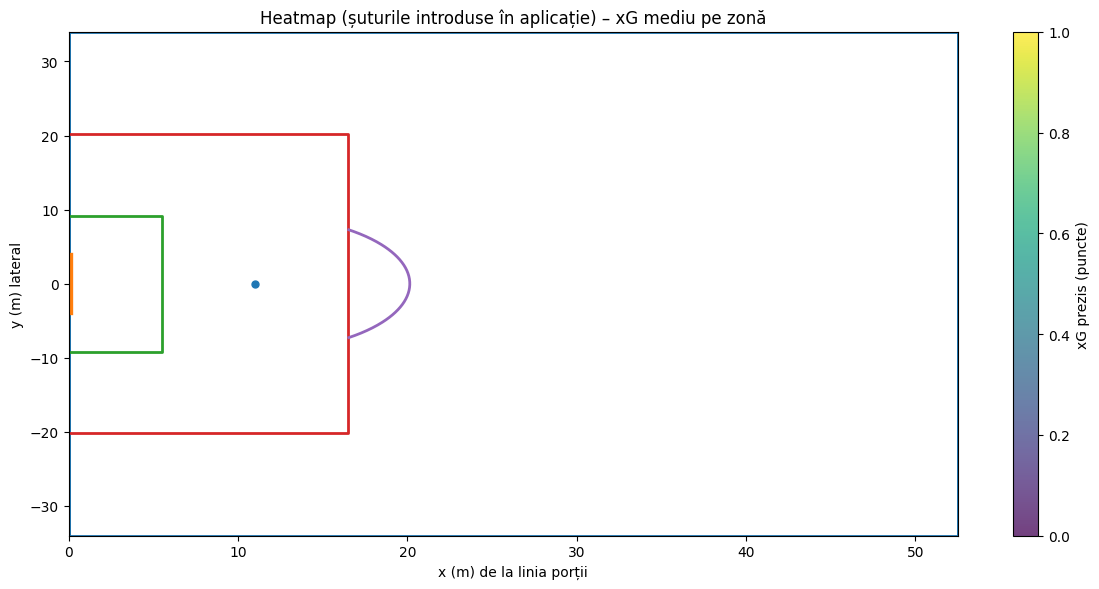

Prea puține șuturi la 30.0° ± 5.0°. Încearcă să mărești ANGLE_TOL (ex. 3–5°) sau introdu mai multe șuturi la acel unghi.


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---- setări ----
MAX_X = 52.5
HALF_W = 34.0            # 68/2
ANGLE_FIXED = 30.0       # unghiul fix (grade)
ANGLE_TOL = 5.0          # toleranță (±1°) – ajustează dacă ai puține puncte

# ---- găsește shot_log.csv ----
candidates = [
    Path.cwd() / "shot_log.csv",
    Path.cwd() / "data" / "shot_log.csv",
    Path.cwd().parent / "data" / "shot_log.csv",
]
log_path = next((p for p in candidates if p.exists()), None)
if log_path is None:
    raise FileNotFoundError("Nu găsesc shot_log.csv. Trimite câteva șuturi în aplicație întâi.")

df = pd.read_csv(log_path, header=None, names=["distance", "angle", "body_part", "xg_pred"], skiprows=1)

# coloane necesare
required = {"distance", "angle", "body_part", "xg_pred"}
if not required.issubset(df.columns):
    raise ValueError(f"shot_log.csv trebuie să conțină {sorted(required)}. Găsite: {list(df.columns)}")

# ---- (1) HEATMAP pe half-pitch bazat pe șuturile tale ----
theta = np.deg2rad(df["angle"].to_numpy())
dist = df["distance"].to_numpy()
xg = df["xg_pred"].to_numpy()

# conversie (distance, angle) -> (x,y) (asumând angle ca "bearing" față de axa centrală)
x = dist * np.cos(theta)
y = dist * np.sin(theta)

# oglindim stânga/dreapta
x_all = np.concatenate([x, x])
y_all = np.concatenate([y, -y])
xg_all = np.concatenate([xg, xg])

# binning pe zone
plt.figure(figsize=(12, 6))

# Buline: culoare = xG prezis (xg_pred)
sc = plt.scatter(x_all, y_all, c=xg_all, s=35, alpha=0.75)

plt.colorbar(sc, label="xG prezis (puncte)")




ax = plt.gca()
draw_half_pitch(ax, length=52.5, width=68.0)
ax.set_xlim(0, 52.5)
ax.set_ylim(-34, 34)

plt.xlabel("x (m) de la linia porții")
plt.ylabel("y (m) lateral")
plt.title("Heatmap (șuturile introduse în aplicație) – xG mediu pe zonă")
plt.tight_layout()
plt.show()

# ---- (2) GRAFIC: xG (Oy) vs distanță (Ox) pentru un unghi fix ----
df_fixed = df[np.abs(df["angle"] - ANGLE_FIXED) <= ANGLE_TOL].copy()

if len(df_fixed) < 5:
    print(f"Prea puține șuturi la {ANGLE_FIXED}° ± {ANGLE_TOL}°. "
          f"Încearcă să mărești ANGLE_TOL (ex. 3–5°) sau introdu mai multe șuturi la acel unghi.")
else:
    # opțional: bin pe distanță ca să vezi evoluția mai clar
    df_fixed["dist_bin"] = pd.cut(df_fixed["distance"], bins=np.arange(0, 53, 1), right=False)
    series = df_fixed.groupby("dist_bin")["xg_pred"].mean().dropna()

    x_centers = np.array([b.left + 0.5 for b in series.index])

    plt.figure(figsize=(8, 4))
    plt.plot(x_centers, series.to_numpy(), marker="o")
    plt.xlabel("Distanța (m)")
    plt.ylabel("xG prezis (medie)")
    plt.title(f"Evoluția xG vs distanță la unghi ~ {ANGLE_FIXED}° (±{ANGLE_TOL}°)")
    plt.tight_layout()
    plt.show()